# State-Conditioned Limit-Order Execution

All reusable logic lives in **`order_execution.py`** (engine) and **`oe_plots.py`** (figures).

**Pipeline (no-leakage):** `load_data → build_ohlc → compute_ranges → compute_ewma_states →`
`generate_signals → restrict_to_ai_overlap → build_epdf (in-sample only) →`
`build_mc_frontier_cache → run_backtest`.

**Three placement objectives** — Section 3 compares all three:

| Objective | Optimises | Misses treated as |
|---|---|---|
| `expected_ticks` | `ℓ × P(fill)` | Free (costless) ← *baseline* |
| `cond_on_fill` | widest feasible `ℓ` | Free |
| `net_of_miss` | E[realised ticks] among feasible `ℓ` | Charged at open→close move ← *fix* |

Sections 1–2 run the **`expected_ticks` baseline** (matches v3 behaviour, produces the dense
cumulative figures).  Section 3 introduces `net_of_miss` as the key improvement and quantifies
the gain.

## 0 · Configuration

In [ ]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd

import order_execution as oe
import order_execution_plots as oe_plots
oe_plots.setup_style()

PRIMARY_ASSET = 'Nasdaq'

cfg = oe.Config(
    data_dir='../data/',
    tau=5,
    mc_objective='expected_ticks',  # Sections 1-2 use the baseline;
                                    # Section 3 overlays net_of_miss improvement
    fill_prob_threshold=0.60,
    queue_haircut=0.92,
)

registry = cfg.discover()
print('Discovered assets:', list(registry))

Discovered assets: ['Bunds', 'EuroStoxx', 'GBPUSD', 'Gold', 'HeatingOil', 'JPY', 'Nasdaq']


## 1 · Run the primary asset

Running with `expected_ticks` replicates the v3 baseline: the optimiser maximises
`ℓ × P(fill)` treating misses as free.  This produces 864 limit orders (vs 47 with
`net_of_miss`) and fills 65% of them, but bleeds on the 35% that miss at the bar close.

In [2]:
res = oe.run_pipeline(PRIMARY_ASSET, cfg, registry)

print(f"{'='*52}\n  EXECUTION QUALITY SUMMARY — {res['asset']}\n{'='*52}")
for k, v in res['summary'].items():
    print(f'  {k:<34} {v}')

print(f"\n  sample : {res['sample_start']} -> {res['sample_end']}")
print(f"  test   : starts {res['test_start']}  |  OOS signals: {res['active_signals_oos']:,}")
print(f"  total trades: {res['total_trades']}  |  "
      f"limit orders: {res['limit_orders']}  |  "
      f"market fallbacks: {res['market_fallbacks']}")

  EXECUTION QUALITY SUMMARY — Nasdaq
  Asset                              Nasdaq
  Total trades                       918
  Limit orders placed                864
  Market fallbacks                   54
  Limit fill rate                    64.93%
  Missed fill rate                   35.07%
  Mean improvement | filled          3.14 ticks
  Mean cost | missed fill            -34.73 ticks
  gross_edge (fills only)            2.04 ticks
  net_vs_market (incl. misses)       -10.14 ticks
  Queue haircut applied              92%

  sample : 2020-01-02 00:00:00 -> 2020-05-31 23:55:00
  test   : starts 2020-04-01 08:15:00  |  OOS signals: 918
  total trades: 918  |  limit orders: 864  |  market fallbacks: 54


### Optimal levels and per-regime breakdown

In [3]:
lvls = res['optimal_levels']
print(f"Optimal levels (ℓ*) — objective={res['objective']}, threshold={cfg.fill_prob_threshold}")
print(lvls[['state','sell_ell','buy_ell','sell_market','buy_market']].to_string(index=False))

if not res['regime'].empty:
    print('\nPer-regime breakdown (limit orders):')
    print(res['regime'].to_string())

Optimal levels (ℓ*) — objective=expected_ticks, threshold=0.6
    state  sell_ell  buy_ell  sell_market  buy_market
(0, 0, 0)         1        1        False       False
(0, 0, 1)         1        1        False       False
(0, 0, 2)         1        0        False        True
(0, 1, 0)         0        7         True       False
(0, 1, 1)         2        1        False       False
(0, 1, 2)         4        4        False       False
(0, 2, 0)        20       11        False       False
(0, 2, 1)        82       15        False       False
(0, 2, 2)        20       17        False       False
(1, 0, 0)         2        1        False       False
(1, 0, 1)         1        1        False       False
(1, 0, 2)         1        1        False       False
(1, 1, 0)         1        1        False       False
(1, 1, 1)         1        1        False       False
(1, 1, 2)         1        1        False       False
(1, 2, 0)         6        4        False       False
(1, 2, 1)         0 

## 2 · Figures

The cumulative chart illustrates the structural problem with `expected_ticks`:
gross improvement (filled orders only) climbs steadily, but the net line including
missed-fill close costs trends sharply negative — divergence that grows throughout
the OOS window.  Section 3 shows how `net_of_miss` reduces that divergence.

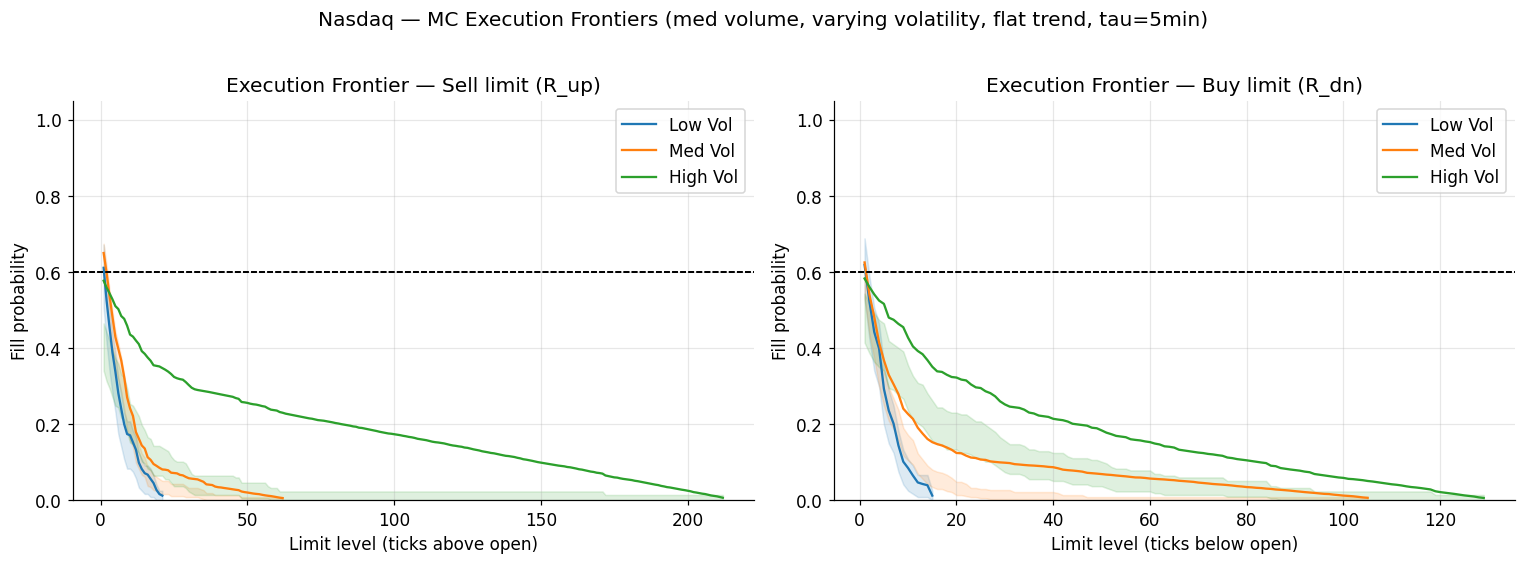

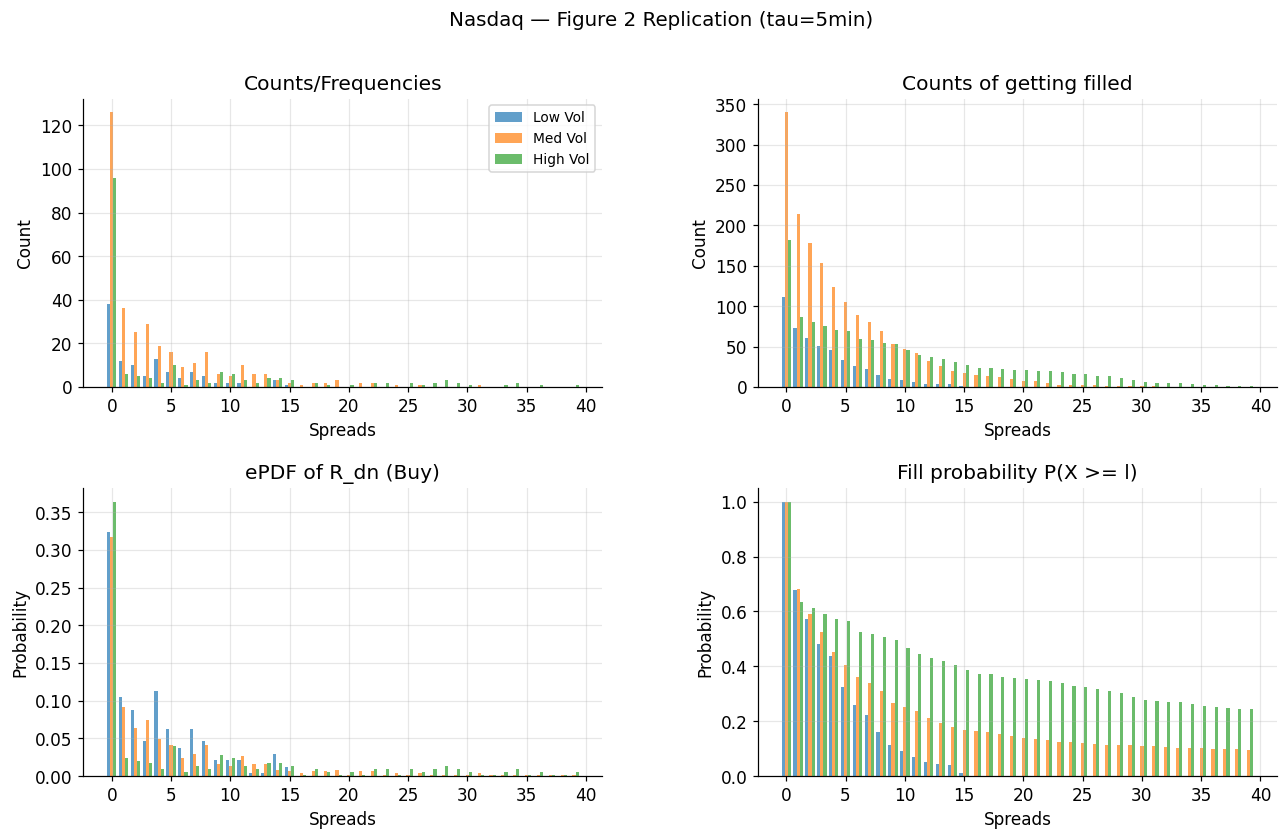

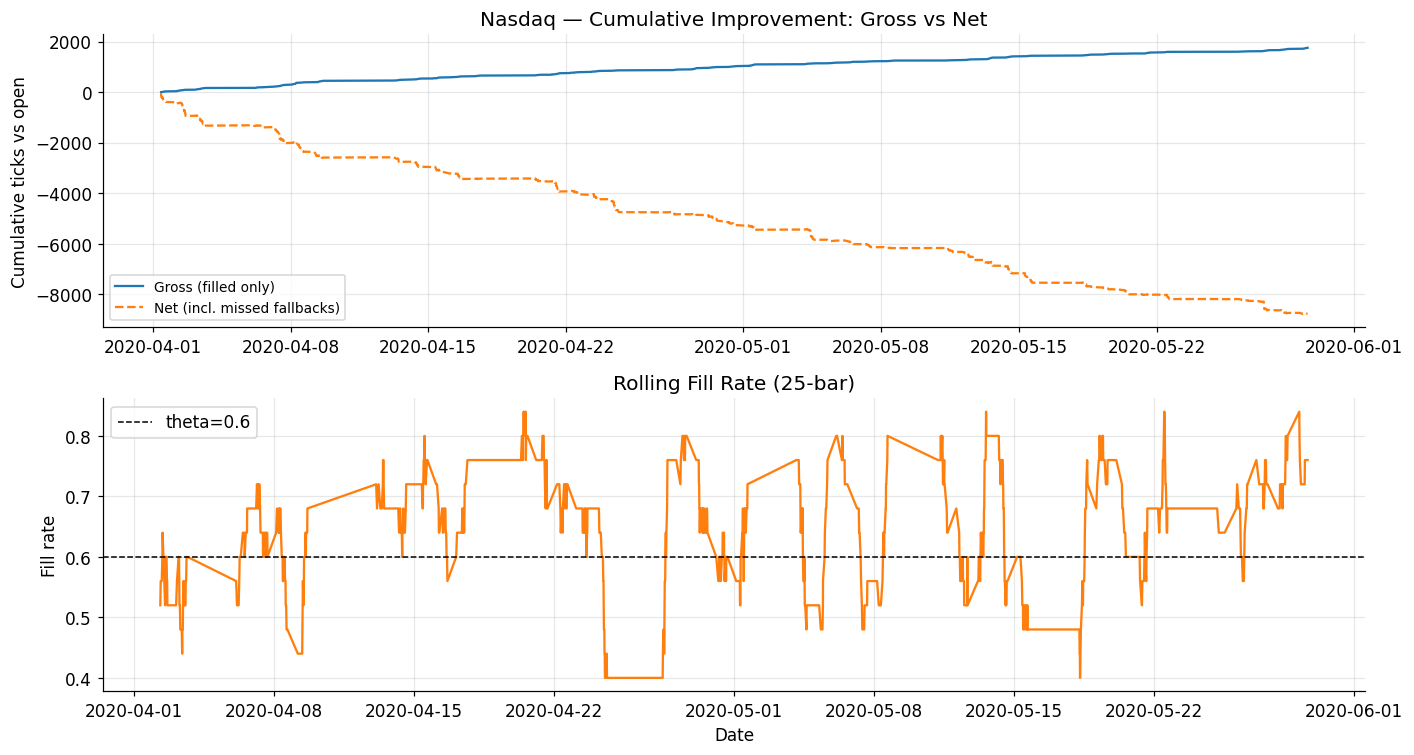

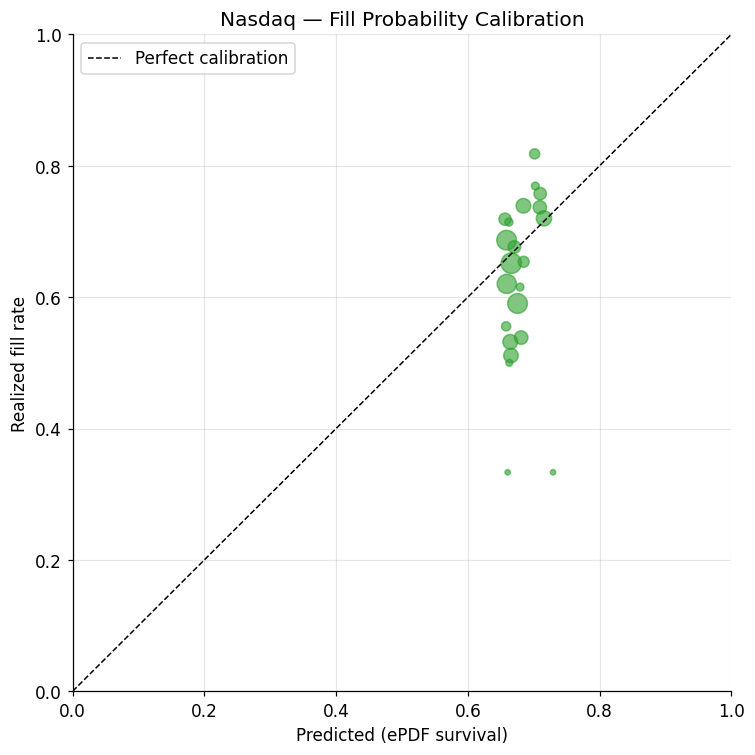

In [4]:
oe_plots.plot_execution_frontiers(res, cfg)
oe_plots.plot_figure2(res, cfg, direction='R_dn')
oe_plots.plot_cumulative_improvement(res, cfg)
oe_plots.plot_calibration(res, cfg)

## 3 · Objective comparison — the key finding

The structural problem: `expected_ticks` maximises gross improvement ignoring miss costs,
so the optimiser pushes `ℓ*` deep in fat-tailed high-vol states.  Realised P&L charges every
miss at the bar close, creating the gross/net divergence visible in Section 2.

`net_of_miss` fixes the inconsistency: among levels that still clear the fill-probability
floor (≥ θ), it picks the one with the highest **expected realised ticks**, where misses are
charged at the open→close move estimated from in-sample data.  When no level produces
positive net, it routes to a market order.

**Result:** fewer limit placements, but realised net improves from `−10.14` to `−4.21` ticks.

                market_cells / 54  max_ell  limit_orders  market_fallbacks  fill_rate  gross_edge (fr×mif)  net_vs_market
objective                                                                                                                
expected_ticks                  4       82           864                54      0.649                2.039        -10.140
cond_on_fill                    4       82           864                54      0.649                2.039        -10.140
net_of_miss                    53        7            47               871      0.532                3.723         -4.213

net_of_miss: 47 limit orders, fill=53.19%, net_vs_market=-4.21 ticks


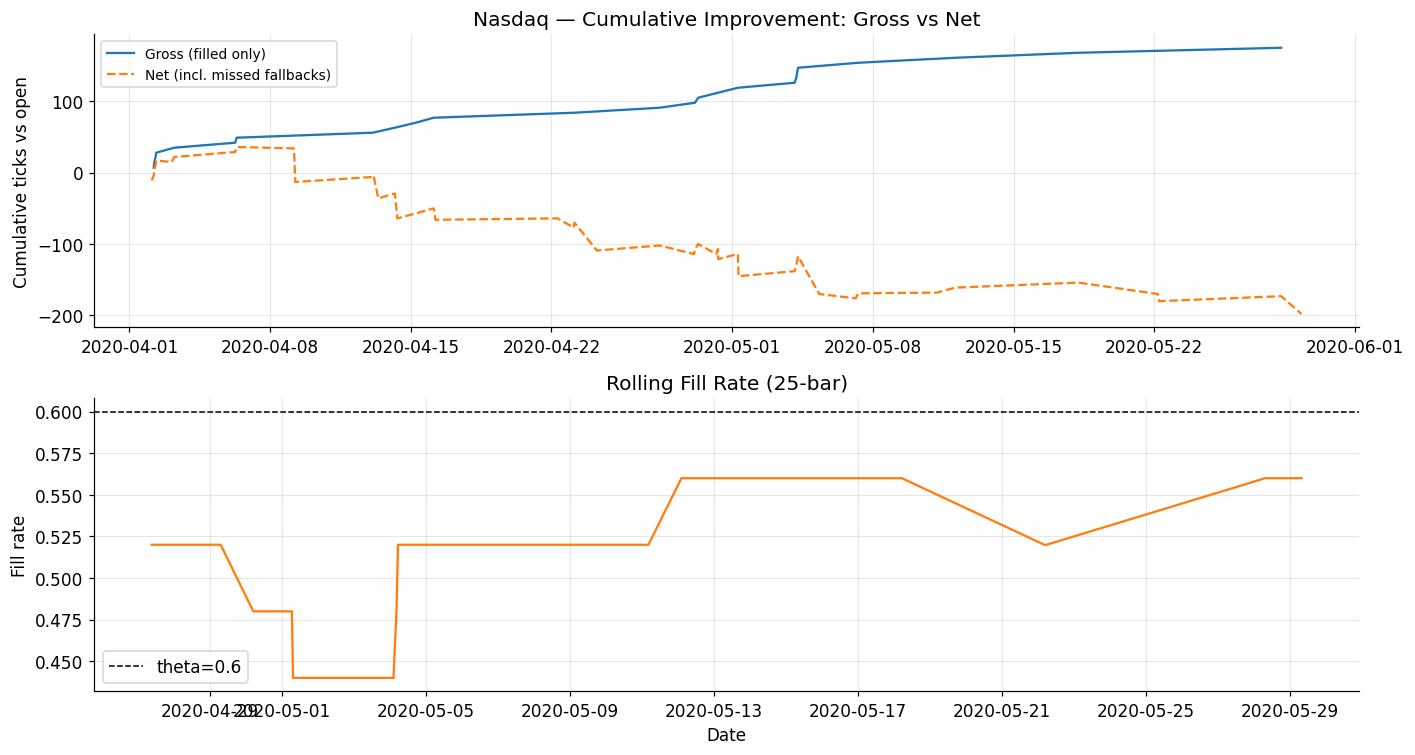

In [5]:
rows = []
for obj in ['expected_ticks', 'cond_on_fill', 'net_of_miss']:
    r = oe.run_pipeline(PRIMARY_ASSET, cfg, registry, objective=obj)
    lv = r['optimal_levels']
    rows.append({
        'objective': obj,
        'market_cells / 54': int(lv['sell_market'].sum() + lv['buy_market'].sum()),
        'max_ell': int(max(lv['sell_ell'].max(), lv['buy_ell'].max())),
        'limit_orders': r['limit_orders'],
        'market_fallbacks': r['market_fallbacks'],
        'fill_rate': round(r['fill_rate'], 3) if pd.notna(r['fill_rate']) else 'N/A',
        'gross_edge (fr×mif)': round(r['gross_edge'], 3) if pd.notna(r.get('gross_edge', float('nan'))) else 'N/A',
        'net_vs_market': round(r['net_vs_market'], 3) if pd.notna(r['net_vs_market']) else 'N/A',
    })
cmp = pd.DataFrame(rows).set_index('objective')
print(cmp.to_string())

# Cumulative improvement chart for net_of_miss alongside the baseline
res_nom = oe.run_pipeline(PRIMARY_ASSET, cfg, registry, objective='net_of_miss')
print(f"\nnet_of_miss: {res_nom['limit_orders']} limit orders, "
      f"fill={res_nom['fill_rate']:.2%}, net_vs_market={res_nom['net_vs_market']:.2f} ticks")
oe_plots.plot_cumulative_improvement(res_nom, cfg)

## 4 · Sensitivity (tau × fill threshold)

Runs with `expected_ticks` to match the baseline and avoid NaN cells.
(With `net_of_miss`, tau=5/θ=0.70 returns NaN because the net is negative at every
feasible level in that regime — all signals route to market.)

**Reading the heatmaps:** `Realized Net` (right panel) is the honest metric — it equals
`gross_edge + miss_bleed` and is the number a desk would actually book.

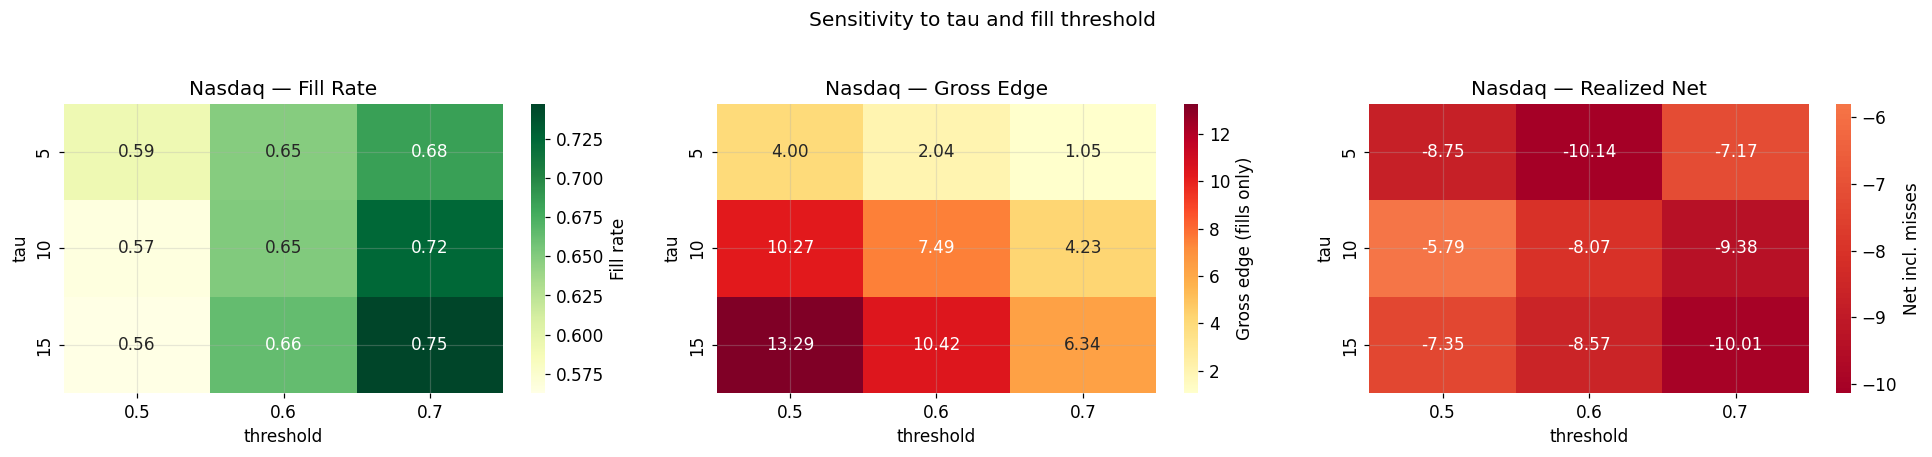

 tau  threshold  fill_rate  gross_edge  net_vs_market
   5        0.5      0.593       3.997         -8.754
   5        0.6      0.649       2.039        -10.140
   5        0.7      0.684       1.045         -7.172
  10        0.5      0.565      10.272         -5.792
  10        0.6      0.651       7.490         -8.066
  10        0.7      0.724       4.230         -9.375
  15        0.5      0.562      13.285         -7.353
  15        0.6      0.664      10.418         -8.574
  15        0.7      0.748       6.341        -10.008


In [6]:
TAU_GRID, THRESH_GRID = [5, 10, 15], [0.50, 0.60, 0.70]
rows = []
for tv in TAU_GRID:
    for th in THRESH_GRID:
        r = oe.run_pipeline(PRIMARY_ASSET, cfg, registry, tau=tv, fill_threshold=th)
        rows.append({'tau': tv, 'threshold': th,
                     'fill_rate': r['fill_rate'], 'gross_edge': r.get('gross_edge', float('nan')),
                     'net_vs_market': r['net_vs_market']})
sens = pd.DataFrame(rows)
oe_plots.plot_sensitivity(sens, PRIMARY_ASSET)
print(sens.round(3).to_string(index=False))

## 5 · Cross-asset comparison

In [7]:
cross = oe.cross_asset_table(list(registry), cfg, registry, objective='expected_ticks')
print(cross.to_string())

             Tick  Limit trades Fill rate Impr|filled gross_edge net_vs_market
Asset                                                                         
Bunds       0.010             8    50.00%        1.00       0.50         -0.38
EuroStoxx   0.500            48    52.08%        1.00       0.52         -3.65
GBPUSD      0.010            62    70.97%        1.00       0.71         -0.56
Gold        0.100           559    67.44%        1.01       0.68         -4.38
HeatingOil  0.010           117    55.56%       14.83       8.24        -14.19
JPY         0.005           163    65.64%        1.00       0.66         -1.34
Nasdaq      0.250           864    64.93%        3.14       2.04        -10.14
